# Student Performance Prediction Using Machine Learning
**Course:** CSE570 - Machine Learning with Python
**Dataset:** UCI Student Performance (`student-mat.csv`, Mathematics)
**Task:** Regression - predict the final grade **G3** (0-20) **without** using the earlier grades G1 and G2.

This notebook walks through the full workflow. The heavy lifting lives in `src/`, so the notebook stays short and readable:

| Phase | File |
|---|---|
| 1-2 Loading, auditing, cleaning, preprocessing | `src/data_preprocessing.py` |
| 3 EDA + statistical tests | `src/exploratory_analysis.py` |
| 4-7 Models, evaluation, tuning, saving | `src/train_model.py` |
| Prediction helper | `src/predict.py` |

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # so we can import the src package

import pandas as pd
import numpy as np
from IPython.display import Image, display

from src.data_preprocessing import (load_raw_data, audit_data, clean_data, find_outliers_iqr,
    get_features_and_target, split_data, build_preprocessor,
    NUMERICAL_FEATURES, CATEGORICAL_FEATURES, FIGURES_DIR)
pd.set_option("display.max_columns", 40)

## Phase 1 - Load and understand the data
The UCI file uses **`;`** as the separator, so `pd.read_csv(path, sep=';')` is used.

In [2]:
raw = load_raw_data()
raw.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


In [3]:
audit = audit_data(raw)
print("Rows x columns:", raw.shape)
print("Missing values in total:", audit["missing_values_total"])
print("Duplicate rows:", audit["duplicate_rows"])
raw.dtypes.value_counts()

Rows x columns: (395, 33)
Missing values in total: 0
Duplicate rows: 0


object    17
int64     16
Name: count, dtype: int64

In [4]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


**Observations**
- 395 students, 33 columns: 16 numeric + 17 text columns. No missing values and no duplicate rows.
- Target: `G3` (final grade 0-20). `G1` and `G2` are earlier grades of the same year and are **excluded from the model inputs**: they are almost the same as G3 (r = 0.80 and 0.90), so using them would make the task trivial and the model useless early in the year.

## Phase 2 - Cleaning and preprocessing

In [5]:
df = clean_data(raw)
print("Shape after cleaning:", df.shape)
for col in ["age", "absences", "failures", "G3"]:
    out = find_outliers_iqr(df[col])
    print(f"{col:9s}: {len(out):3d} IQR outliers -> values {sorted(out.unique().tolist())}")
print("Students with G3 = 0:", (df.G3 == 0).sum())

Shape after cleaning: (395, 33)
age      :   1 IQR outliers -> values [22]
absences :  15 IQR outliers -> values [21, 22, 23, 24, 25, 26, 28, 30, 38, 40, 54, 56, 75]
failures :  83 IQR outliers -> values [1, 2, 3]
G3       :   0 IQR outliers -> values []
Students with G3 = 0: 38


**Decisions**
- **Missing values / duplicates:** none in the file; `clean_data()` still handles them (median/mode fill, drop duplicates) so the code is safe.
- **Data types:** all numeric columns are converted with `pd.to_numeric` and every value is checked against the official ranges.
- **Outliers:** absences up to 75 and age 22 are *possible, real values*, so they are **kept** (not deleted). The 83 "outliers" in `failures` are only flagged because most students have 0 failures - they are valid.
- **G3 = 0 (38 students):** kept, because it is a real recorded outcome. EDA below shows these students most likely did not sit the final exam.

In [6]:
X, y = get_features_and_target(df)
X_train, X_test, y_train, y_test = split_data(X, y)
print("Features used:", X.shape[1], "| G1/G2 in features?", {"G1", "G2"} & set(X.columns))
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Numerical :", NUMERICAL_FEATURES)
print("Categorical:", CATEGORICAL_FEATURES)

Features used: 30 | G1/G2 in features? set()
Train: (316, 30)  Test: (79, 30)
Numerical : ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']
Categorical: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [7]:
pre = build_preprocessor().fit(X_train)          # fitted on TRAINING data only
print("Columns after one-hot encoding:", len(pre.get_feature_names_out()))
pd.DataFrame(pre.transform(X_train.head(3)), columns=pre.get_feature_names_out()).iloc[:, :18].round(2)

Columns after one-hot encoding:

 56


,num__age,num__Medu,num__Fedu,num__traveltime,num__studytime,num__failures,num__famrel,num__freetime,num__goout,num__Dalc,num__Walc,num__health,num__absences,cat__school_GP,cat__school_MS,cat__sex_F,cat__sex_M,cat__address_R
0,-0.59,0.25,0.42,-0.63,-0.06,-0.46,0.06,-1.20,-0.14,-0.55,-0.27,-0.37,-0.46,1.0,0.0,0.0,1.0,0.0
1,-0.59,-0.68,0.42,0.83,-1.25,-0.46,1.20,-0.21,-0.14,-0.55,-1.04,-0.37,-0.70,1.0,0.0,0.0,1.0,0.0
2,-0.59,-1.61,0.42,-0.63,-0.06,3.63,0.06,-0.21,1.64,-0.55,-1.04,-0.37,-0.70,1.0,0.0,1.0,0.0,0.0


`StandardScaler` turns each number into *(value - training mean) / training std*; `OneHotEncoder` turns each category into 0/1 columns.
Inside the model **Pipeline** these are re-fitted on the training folds only, which prevents **data leakage**.

## Phase 3 - Exploratory Data Analysis

In [8]:
from src.exploratory_analysis import run_full_eda, descriptive_statistics
eda = run_full_eda(df)
descriptive_statistics(df)

Saved 12 figures to D:\CSE570\Student-performance-prediction\reports\figures
Saved statistics to D:\CSE570\Student-performance-prediction\reports\eda_results.json


,mean,median,std,min,max
age,16.70,17.0,1.28,15,22
Medu,2.75,3.0,1.09,0,4
Fedu,2.52,2.0,1.09,0,4
traveltime,1.45,1.0,0.70,1,4
studytime,2.04,2.0,0.84,1,4
failures,0.33,0.0,0.74,0,3
famrel,3.94,4.0,0.90,1,5
freetime,3.24,3.0,1.00,1,5
goout,3.11,3.0,1.11,1,5
Dalc,1.48,1.0,0.89,1,5


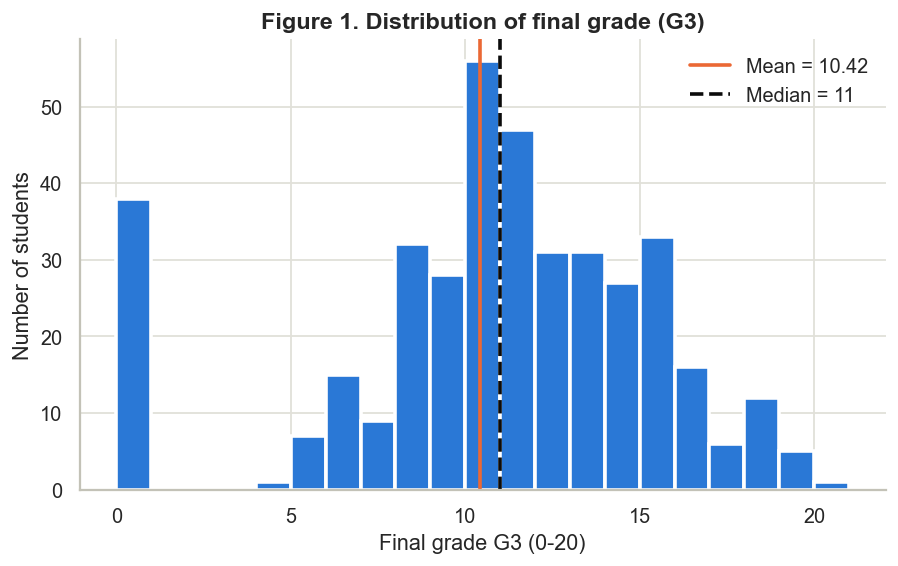

In [9]:
display(Image(filename=str(FIGURES_DIR / "01_g3_distribution.png")))

**Univariate - G3.** Mean 10.42, median 11, 95% CI for the mean [9.96, 10.87]. The distribution is roughly bell-shaped between 4 and 20 but has a separate spike of 38 zeros, so it is not normal (Shapiro-Wilk p < 0.001). That is why non-parametric tests are also used.

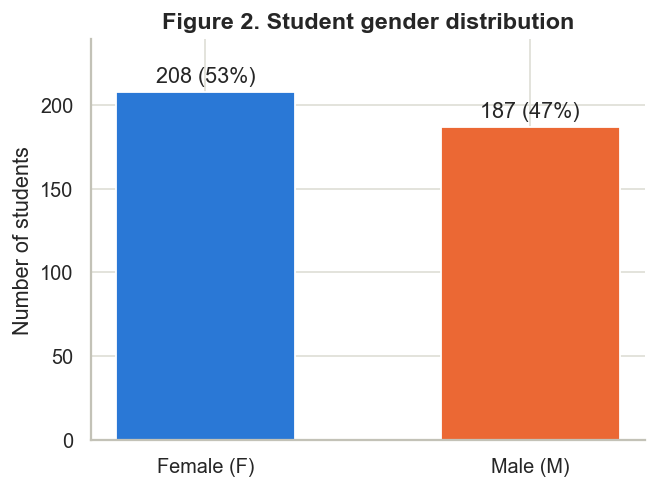

In [10]:
display(Image(filename=str(FIGURES_DIR / "02_gender_distribution.png")))

**Gender.** 208 female (53%) and 187 male (47%) students - fairly balanced.

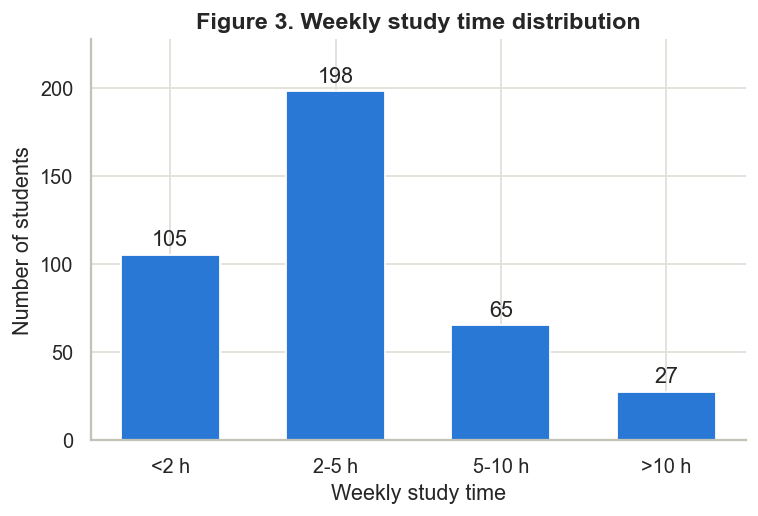

In [11]:
display(Image(filename=str(FIGURES_DIR / "03_studytime_distribution.png")))

**Study time.** Most students study 2-5 h per week (198); only 27 study more than 10 h.

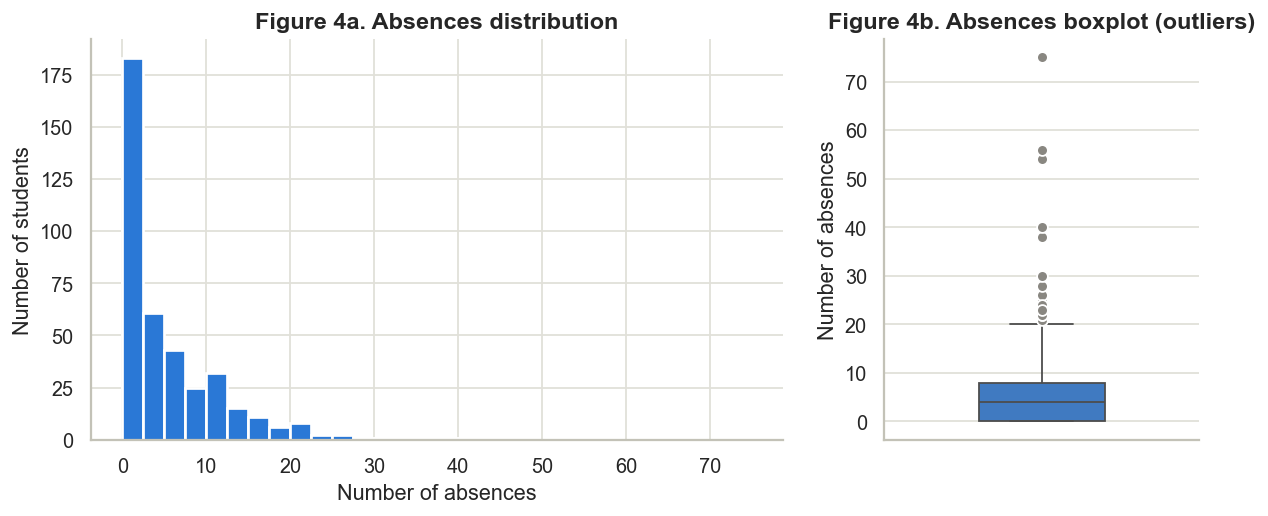

In [12]:
display(Image(filename=str(FIGURES_DIR / "04_absences_distribution.png")))

**Absences.** Strongly right-skewed: median 4, mean 5.7, max 75. 15 students are IQR outliers (more than 20 absences). They are kept because they are real values.

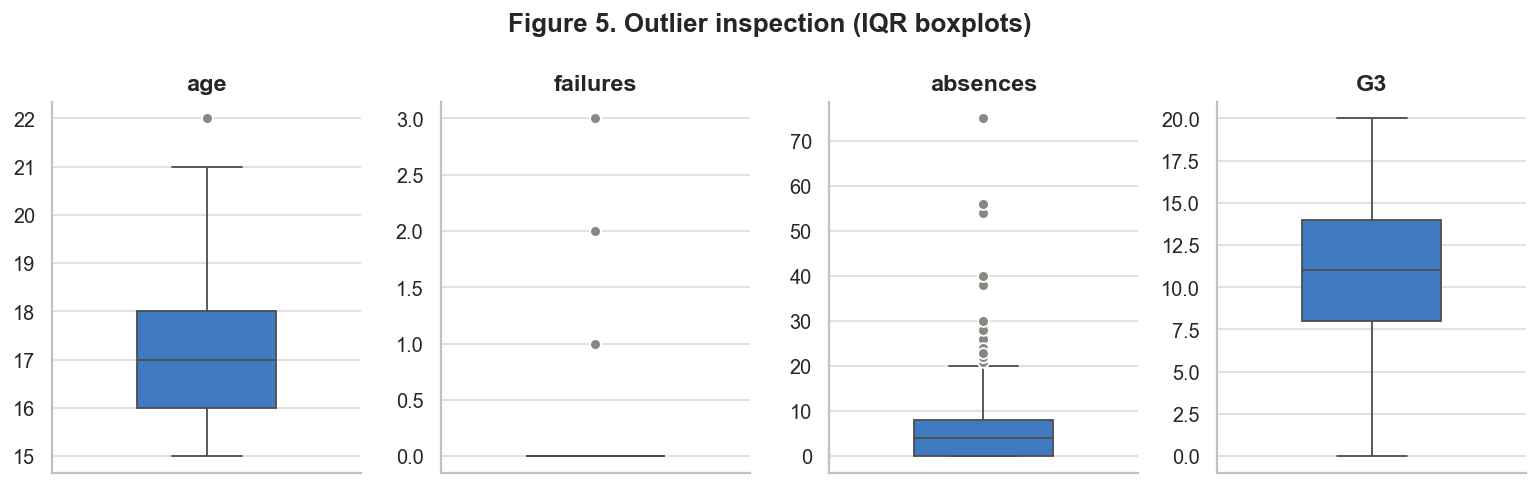

In [13]:
display(Image(filename=str(FIGURES_DIR / "05_outlier_boxplots.png")))

**Outlier inspection** for age, failures, absences and G3. No values outside the official ranges were found.

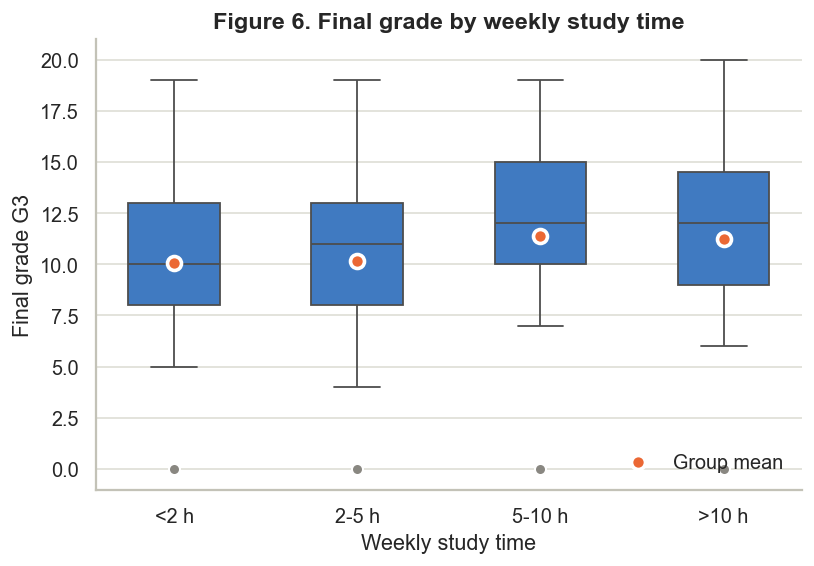

In [14]:
display(Image(filename=str(FIGURES_DIR / "06_g3_by_studytime.png")))

**Bivariate - G3 by study time.** Means rise from 10.0 (<2 h) to 11.4 (5-10 h), but the difference is **not statistically significant** (ANOVA p = 0.16, Kruskal-Wallis p = 0.056). More study time is associated with slightly higher grades, but the effect is small.

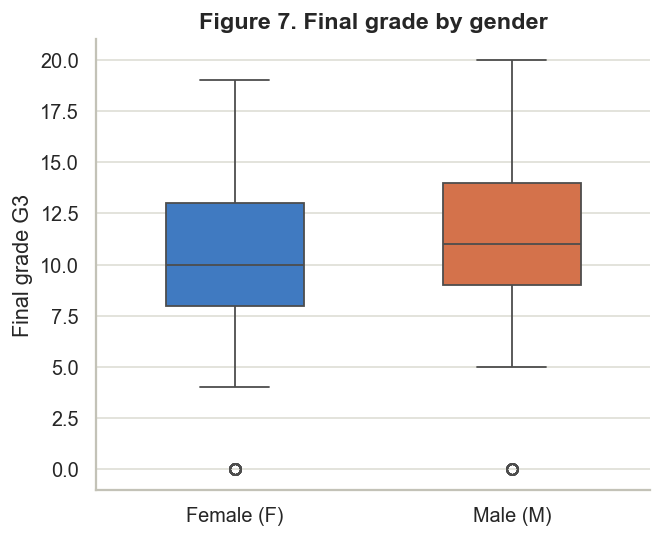

In [15]:
display(Image(filename=str(FIGURES_DIR / "07_g3_by_gender.png")))

**G3 by gender.** Male mean 10.91 vs female mean 9.97. Welch t-test p = 0.040 (< 0.05), a small but significant difference in this sample - this is an association, not a cause.

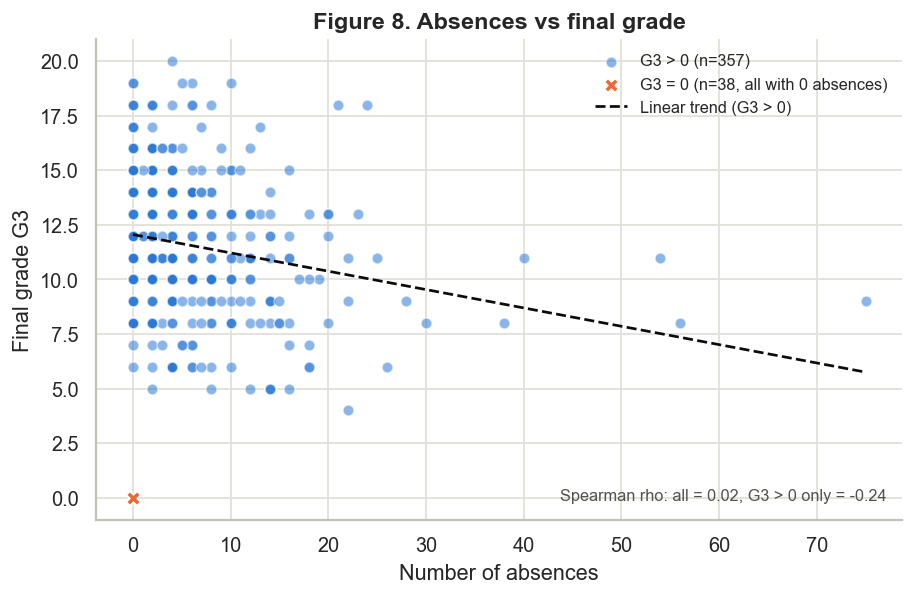

In [16]:
display(Image(filename=str(FIGURES_DIR / "08_absences_vs_g3.png")))

**Absences vs G3 - key insight.** Over all students the correlation is about zero, **but all 38 students with G3 = 0 have exactly 0 absences** (they likely left the course or missed the exam, so absences stopped being recorded). Excluding them, absences correlate negatively with G3 (Spearman rho = -0.24, p < 0.001). This hidden pattern is also why the Random Forest finds `absences` important.

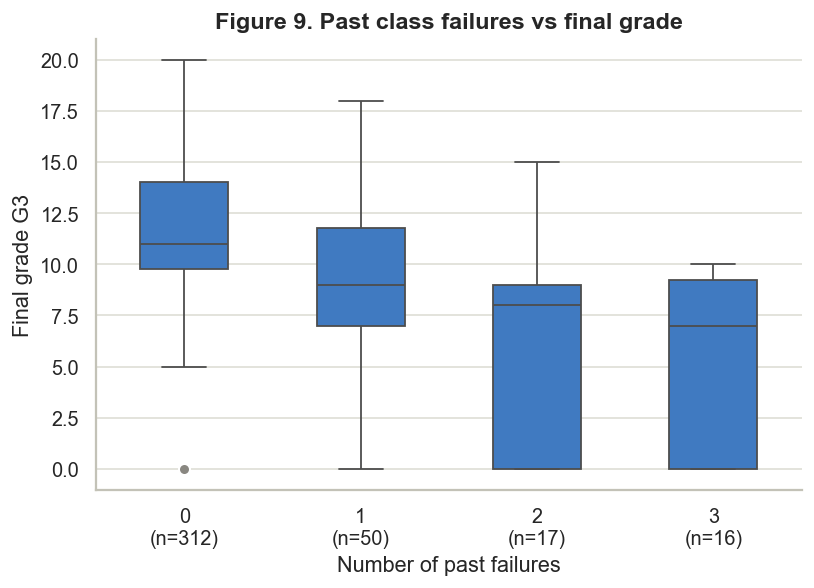

In [17]:
display(Image(filename=str(FIGURES_DIR / "09_failures_vs_g3.png")))

**Failures vs G3.** The clearest relationship: mean G3 falls from 11.3 (0 failures) to 8.1, 6.2 and 5.7 for 1, 2 and 3+ failures (Kruskal-Wallis p < 0.001; Spearman rho = -0.36).

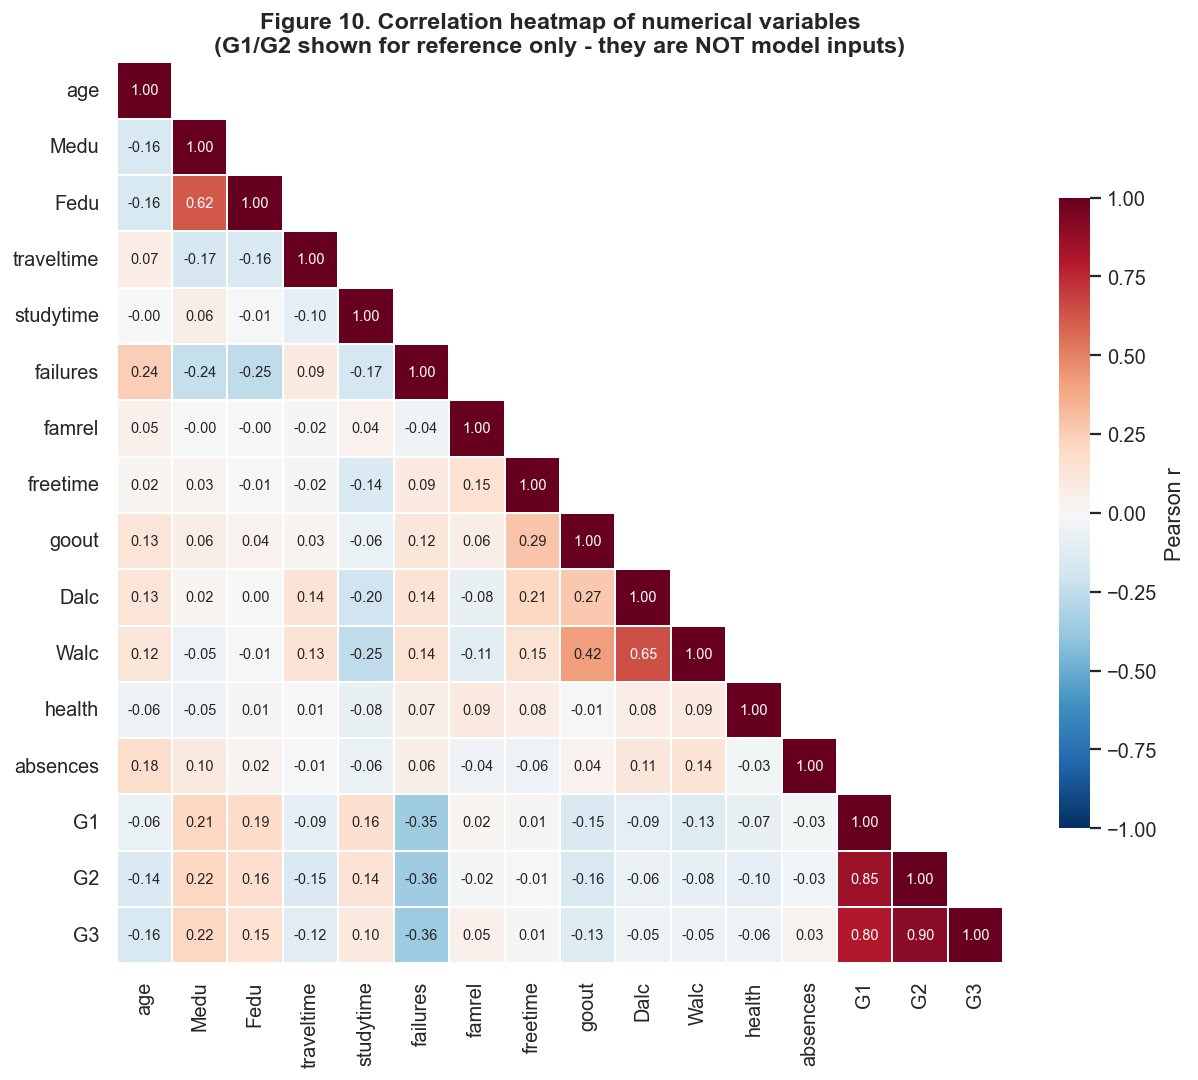

In [18]:
display(Image(filename=str(FIGURES_DIR / "10_correlation_heatmap.png")))

**Multivariate - correlations.** G1, G2 and G3 are very strongly correlated (0.80-0.90), confirming why G1/G2 are excluded. Among inputs, `failures` (-0.36) and mother's education `Medu` (+0.22) are the strongest linear correlates. Medu/Fedu (0.62) and Dalc/Walc (0.65) are correlated pairs (multicollinearity, which Ridge handles better than plain Linear Regression).

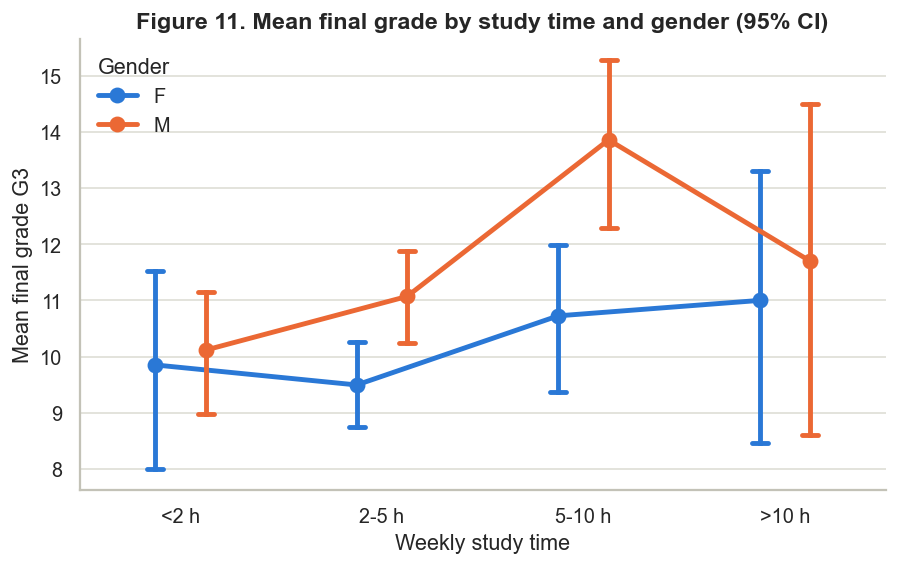

In [19]:
display(Image(filename=str(FIGURES_DIR / "11_g3_studytime_gender.png")))

**Multivariate - study time x gender.** Wide 95% confidence intervals overlap a lot, so study time and gender effects are weak and uncertain.

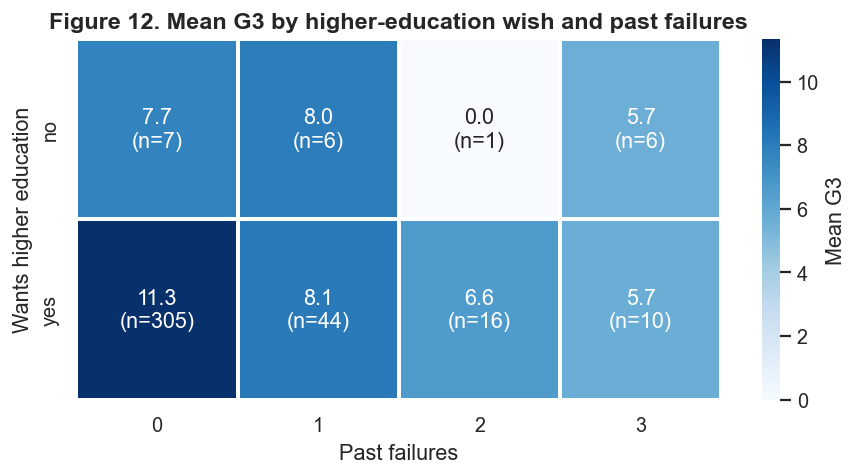

In [20]:
display(Image(filename=str(FIGURES_DIR / "12_g3_higher_failures.png")))

**Multivariate - higher-education wish x failures.** Students who want higher education and have no failures average 11.3. Wanting higher education is associated with passing (pass rate 68.8% vs 35%, chi-square p = 0.004), but only 20 students answered 'no', so this is uncertain.

In [21]:
tests = {
  "95% CI mean G3": eda["g3_mean_ci95"],
  "Welch t-test G3 by sex": {k: eda["ttest_g3_by_sex"][k] for k in ["mean_F", "mean_M", "t_stat", "p_value"]},
  "ANOVA G3 by studytime": {k: eda["anova_g3_by_studytime"][k] for k in ["F_stat", "anova_p_value", "kruskal_p_value"]},
  "Kruskal G3 by failures": {k: eda["kruskal_g3_by_failures"][k] for k in ["H_stat", "p_value"]},
  "Chi-square higher vs pass": {k: eda["chi2_higher_vs_pass"][k] for k in ["chi2", "p_value"]},
}
pd.DataFrame(tests).T

,mean,low,high,mean_F,mean_M,t_stat,p_value,F_stat,anova_p_value,kruskal_p_value,H_stat,chi2
95% CI mean G3,10.41519,9.961992,10.868388,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Welch t-test G3 by sex,NaN,NaN,NaN,9.966346,10.914439,-2.065057,3.957700e-02,NaN,NaN,NaN,NaN,NaN
ANOVA G3 by studytime,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.727835,0.160723,0.055567,NaN,NaN
Kruskal G3 by failures,NaN,NaN,NaN,NaN,NaN,NaN,1.732667e-11,NaN,NaN,NaN,53.11507,NaN
Chi-square higher vs pass,NaN,NaN,NaN,NaN,NaN,NaN,3.850210e-03,NaN,NaN,NaN,NaN,8.353142


In [22]:
corr = pd.DataFrame(eda["correlations_with_g3"]).T.sort_values("spearman_rho")
corr.round(3)

,spearman_rho,p_value,pearson_r
failures,-0.361,0.000,-0.360
age,-0.173,0.001,-0.162
goout,-0.166,0.001,-0.133
Dalc,-0.121,0.016,-0.055
traveltime,-0.121,0.017,-0.117
Walc,-0.104,0.038,-0.052
health,-0.048,0.343,-0.061
freetime,-0.005,0.921,0.011
absences,0.018,0.725,0.034
famrel,0.055,0.276,0.051


In [23]:
group = {f"{col}={k}": v for col, d in eda["group_means_g3"].items() for k, v in d.items()}
pd.DataFrame(group).T.round(2)

,mean,n
sex=F,9.97,208.0
sex=M,10.91,187.0
address=R,9.51,88.0
address=U,10.67,307.0
internet=no,9.41,66.0
internet=yes,10.62,329.0
higher=no,6.80,20.0
higher=yes,10.61,375.0
schoolsup=no,10.56,344.0
schoolsup=yes,9.43,51.0


**EDA summary.** Past failures are the strongest single signal. Mother's education, wanting higher education, going out, age and (for students who sat the exam) absences also relate to G3. Study time, family relationship and health show weak or no relationship. All findings are **associations, not causes**.

## Phases 4-7 - Models, evaluation, tuning and saving
`train_and_evaluate()`:
1. builds 5 pipelines (preprocessing + model): Dummy baseline, Linear Regression, Ridge, Decision Tree, Random Forest;
2. compares them with **5-fold cross-validation on the training set**;
3. picks the best by CV RMSE **and** CV MAE (not R2 alone);
4. tunes it with **GridSearchCV** (training data only);
5. evaluates everything once on the untouched test set and saves the final pipeline to `models/best_model.joblib`.

In [24]:
from src.train_model import train_and_evaluate
metrics = train_and_evaluate(verbose=False)
table = pd.DataFrame(metrics["comparison"]).T
table[["MAE", "MSE", "RMSE", "R2", "CV_MAE", "CV_RMSE", "CV_R2", "Train_RMSE"]].round(3)

,MAE,MSE,RMSE,R2,CV_MAE,CV_RMSE,CV_R2,Train_RMSE
Dummy Regressor (baseline),3.646,20.704,4.550,-0.010,3.403,4.563,-0.035,4.583
Linear Regression,3.395,17.604,4.196,0.141,3.523,4.607,-0.092,3.865
Ridge Regression,3.393,17.585,4.193,0.142,3.506,4.584,-0.080,3.865
Decision Tree,3.633,23.405,4.838,-0.141,4.102,5.527,-0.570,0.000
Random Forest,3.010,14.175,3.765,0.309,2.934,3.925,0.212,1.457
Random Forest (tuned),3.035,14.145,3.761,0.310,2.960,3.897,0.232,1.451


**Model comparison - interpretation**
- **Baseline (Dummy, always predicts the training mean):** test MAE 3.65, RMSE 4.55, R2 = -0.01. Any useful model must beat this.
- **Linear / Ridge Regression:** better than the baseline on the test set (MAE 3.39, R2 0.14) but *worse* in 5-fold CV (CV R2 below 0). Their performance is unstable - a single 79-student test set can be lucky or unlucky, which is why model choice is made with cross-validation. Ridge is slightly more stable than plain Linear Regression because it shrinks coefficients of correlated inputs.
- **Decision Tree (no depth limit):** training RMSE = 0.00 but CV RMSE 5.53 and test R2 < 0 - a textbook case of **overfitting** (it memorised the training students).
- **Random Forest:** best on every metric in CV (CV MAE 2.93, CV RMSE 3.93) and on the test set (MAE 3.01, RMSE 3.77, R2 0.31). Averaging 300 trees reduces the overfitting of a single tree.
- **Tuned Random Forest (final model):** GridSearchCV (54 combinations x 5 folds) chose `max_features=0.5, n_estimators=200, max_depth=None, min_samples_leaf=1`. CV RMSE improved only slightly (3.93 -> 3.90). On the test set RMSE is practically unchanged (3.77 -> 3.76) and MAE is 0.03 worse (3.01 -> 3.04): **tuning gave a very small gain**, and the two versions are essentially equal. The tuned one is kept because it won on cross-validation, which is the fair selection rule (the test set is never used for choices).

In [25]:
print('Best params:', metrics['best_params'])
print('Grid:', metrics['param_grid'])

Best params: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 200}
Grid: {'n_estimators': ['200', '500'], 'max_depth': ['None', '6', '10'], 'min_samples_leaf': ['1', '3', '5'], 'max_features': ['1.0', '0.5', 'sqrt']}


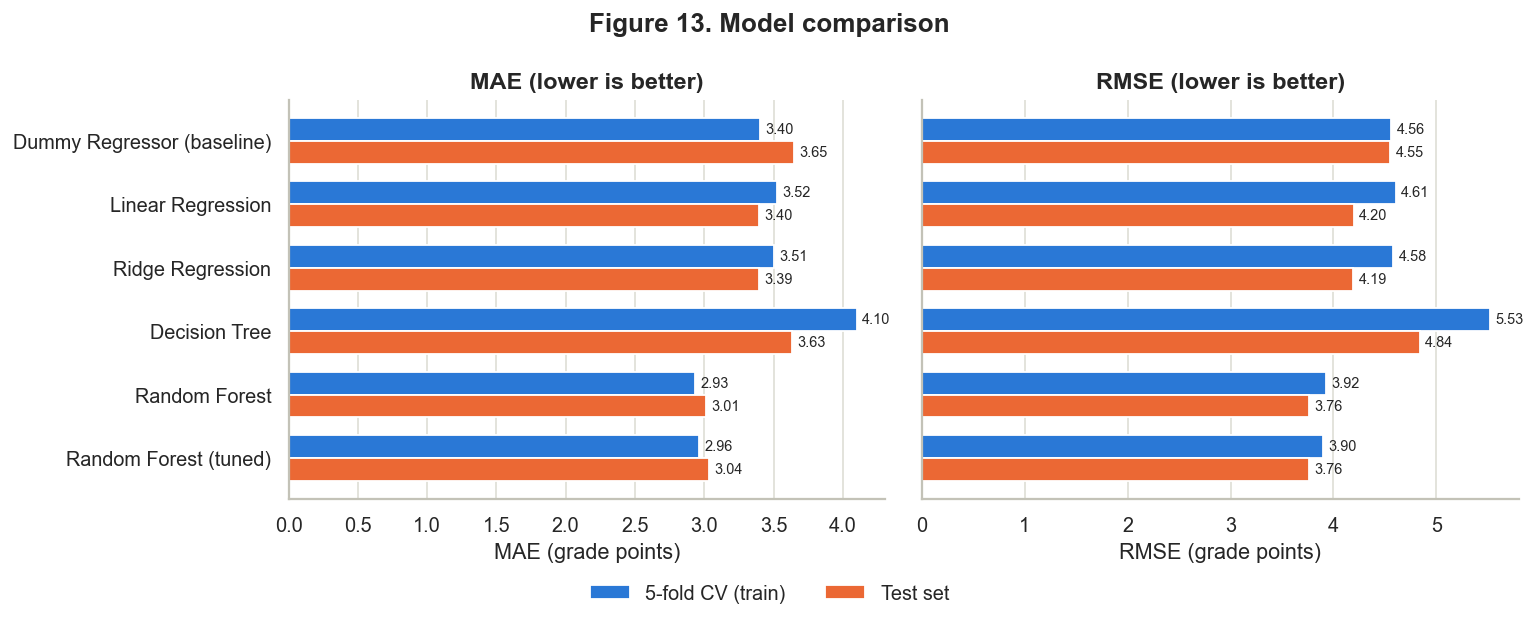

In [26]:
display(Image(filename=str(FIGURES_DIR / "13_model_comparison.png")))

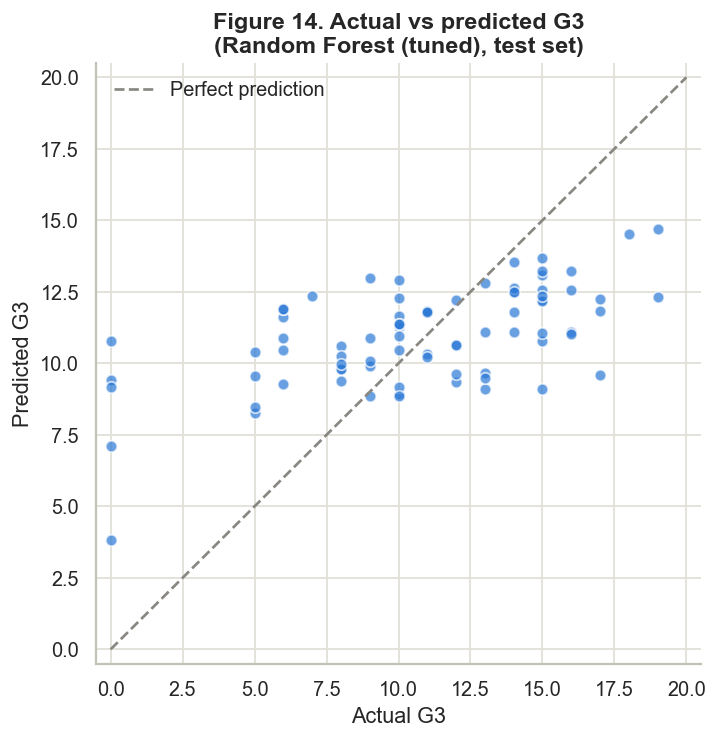

In [27]:
display(Image(filename=str(FIGURES_DIR / "14_actual_vs_predicted.png")))

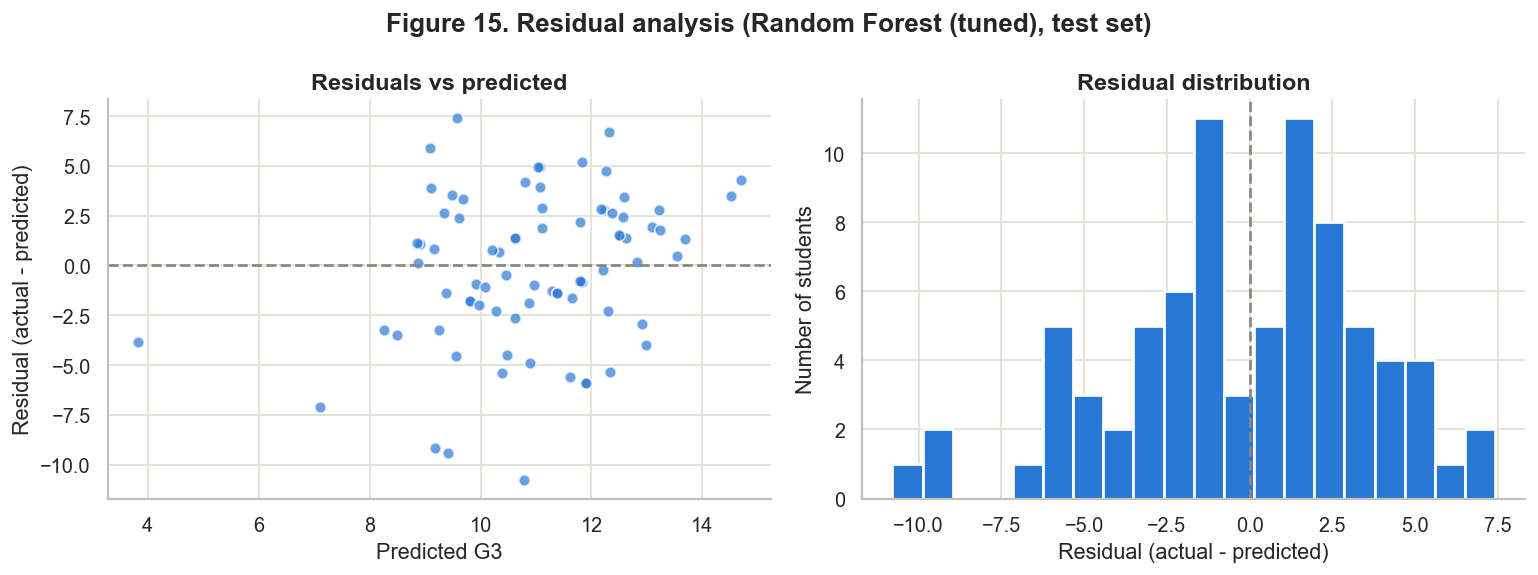

In [28]:
display(Image(filename=str(FIGURES_DIR / "15_residuals.png")))

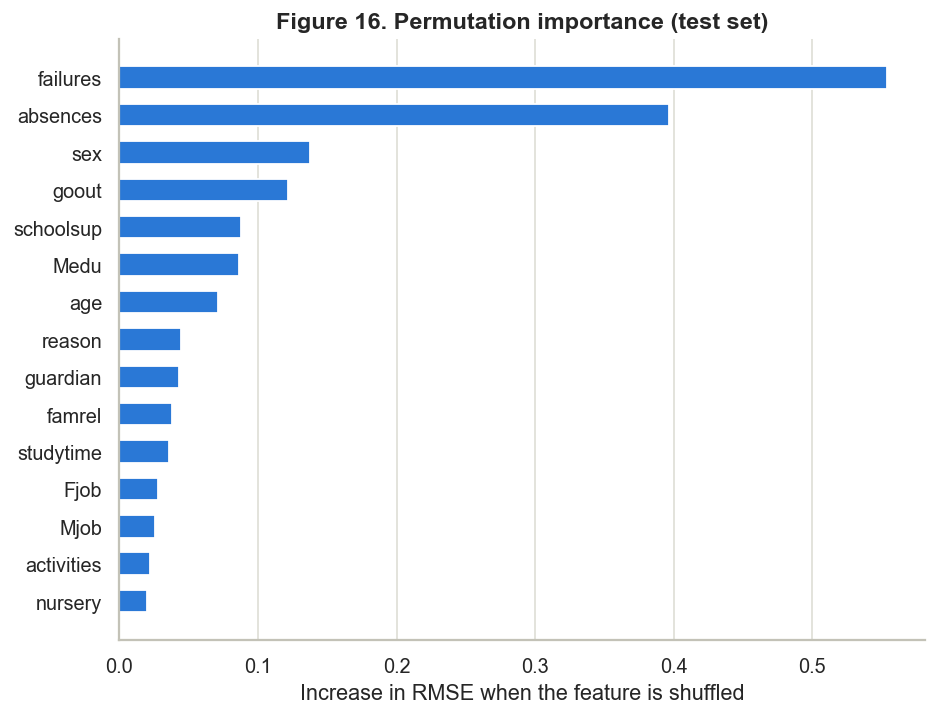

In [29]:
display(Image(filename=str(FIGURES_DIR / "16_permutation_importance.png")))

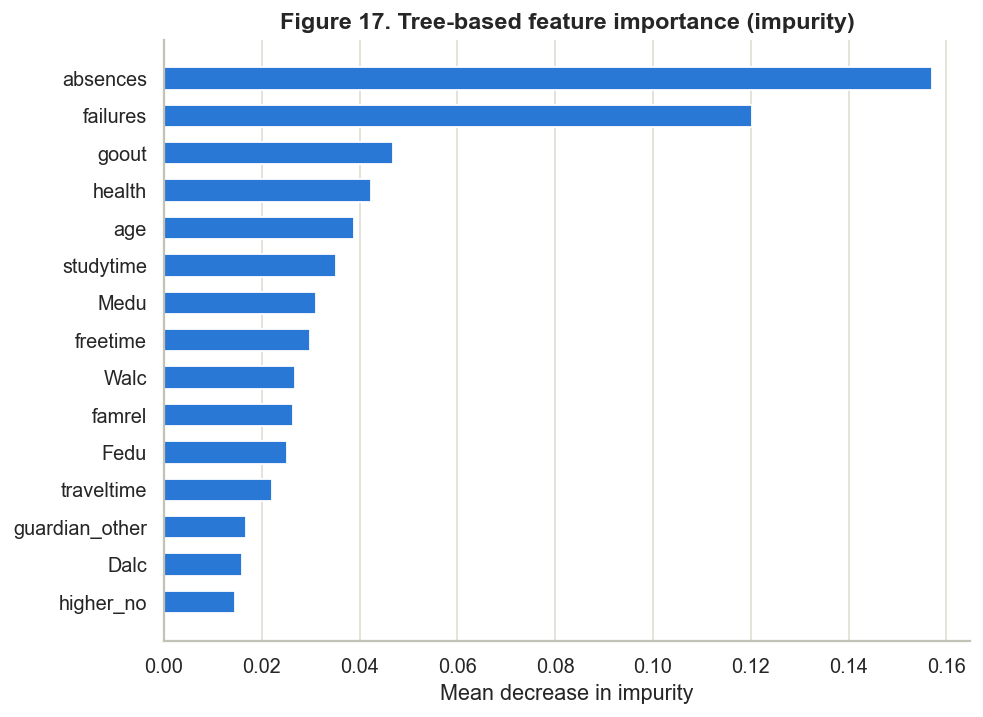

In [30]:
display(Image(filename=str(FIGURES_DIR / "17_tree_feature_importance.png")))

**Model behaviour**
- **Actual vs predicted:** predictions are squeezed towards the middle (about 8-14). The model rarely predicts very high or very low grades - typical for a model with modest R2.
- **Residuals:** centred near 0 (mean residual -0.18), so no strong overall bias. 43% of test predictions are within 2 points and 73% within 4 points.
- **The G3 = 0 students are the main error source:** for the 5 test students with G3 = 0 the mean absolute error is **8.06**, against **2.70** for everyone else. The model cannot reliably tell, from background data, who will drop out / miss the exam.
- **Feature importance:** permutation importance (how much test RMSE gets worse when one input is shuffled) ranks `failures` and `absences` far above all others, followed by `sex`, `goout`, `schoolsup` and `Medu`. The Random Forest's own impurity importance agrees (absences, failures, goout, health, age on top). `absences` is important partly because of the "0 absences & G3 = 0" pattern found in EDA.
- **Linear Regression coefficients** (inputs are scaled, so sizes are comparable): each extra standard deviation of failures lowers the predicted grade by about 1.36 points; wanting higher education and being male are associated with higher predictions.

In [31]:
pd.Series(metrics["linear_regression_top_coefficients"]).round(3).to_frame("Linear Regression coefficient (scaled inputs)")

,Linear Regression coefficient (scaled inputs)
failures,-1.362
Mjob_teacher,-1.192
Mjob_health,1.038
Fjob_teacher,0.892
higher_no,-0.875
higher_yes,0.875
sex_F,-0.748
sex_M,0.748
studytime,0.633
famsup_yes,-0.628


## Using the saved model

In [32]:
from src.predict import load_model, predict_grade
model = load_model()
student = X_test.iloc[0].to_dict()
student = {k: (v if isinstance(v, str) else int(v)) for k, v in student.items()}
result = predict_grade(model, student)
print("Actual G3:", y_test.iloc[0], "| Predicted:", round(result["predicted_grade"], 2))

Actual G3: 10 | Predicted: 8.91


## Conclusion
- A tuned Random Forest predicts G3 **without G1/G2** better than the baseline and the linear models, but the error is still about 3 grade points: background information alone gives only a rough estimate.
- The most useful signals are past failures and absences (including the absences = 0 / G3 = 0 dropout pattern).
- Limitations: small dataset (395 students, 79 in the test set), one school subject, two schools in Portugal, self-reported answers, and the G3 = 0 group which behaves differently from all other students.